# Auditoría de calibración finita de Christoffersen

**TL;DR.** Comparamos el p-valor $\chi^2$ usual con una permutación condicional al número de excepciones y su versión aleatorizada. La semilla y todos los resultados se cargan de artefactos generados por `python -m src.main`.

## Contexto y método

La nula exige hits IID. Condicionar en el total elimina la probabilidad Bernoulli desconocida; relocalizamos uniformemente los hits y recalculamos $LR_{ind}$. La versión no aleatorizada cuenta empates como extremos; la aleatorizada rompe empates con una U(0,1). Supuestos: hit binario diario, orden temporal correcto, primer orden Markov como estadístico, sin riesgo de estimación de VaR.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
summary = pd.read_csv(ROOT/'results'/'summary.csv')
run = json.loads((ROOT/'results'/'run.json').read_text())
summary

,scenario,mean_exception_rate,rejection_asymptotic,rejection_permutation,rejection_randomized
0,iid_null,0.010030,0.012,0.0125,0.0480
1,markov_clustered,0.009926,0.413,0.3730,0.4515


## Datos

Dos DGP sintéticos con igual tasa estacionaria objetivo de 1%: Bernoulli IID para medir tamaño y Markov con $P(I_t=1|I_{t-1}=1)=0.35$ para medir potencia. Se usan 250 días, 2.000 trials y 1.999 permutaciones por conteo de excepciones.

In [2]:
pd.DataFrame([run['config']]).T.rename(columns={0: 'valor'})

,valor
n,250.00
probability,0.01
trials,2000.00
permutations,1999.00
cluster_probability,0.35
alpha,0.05
seed,20261021.00


## Resultados

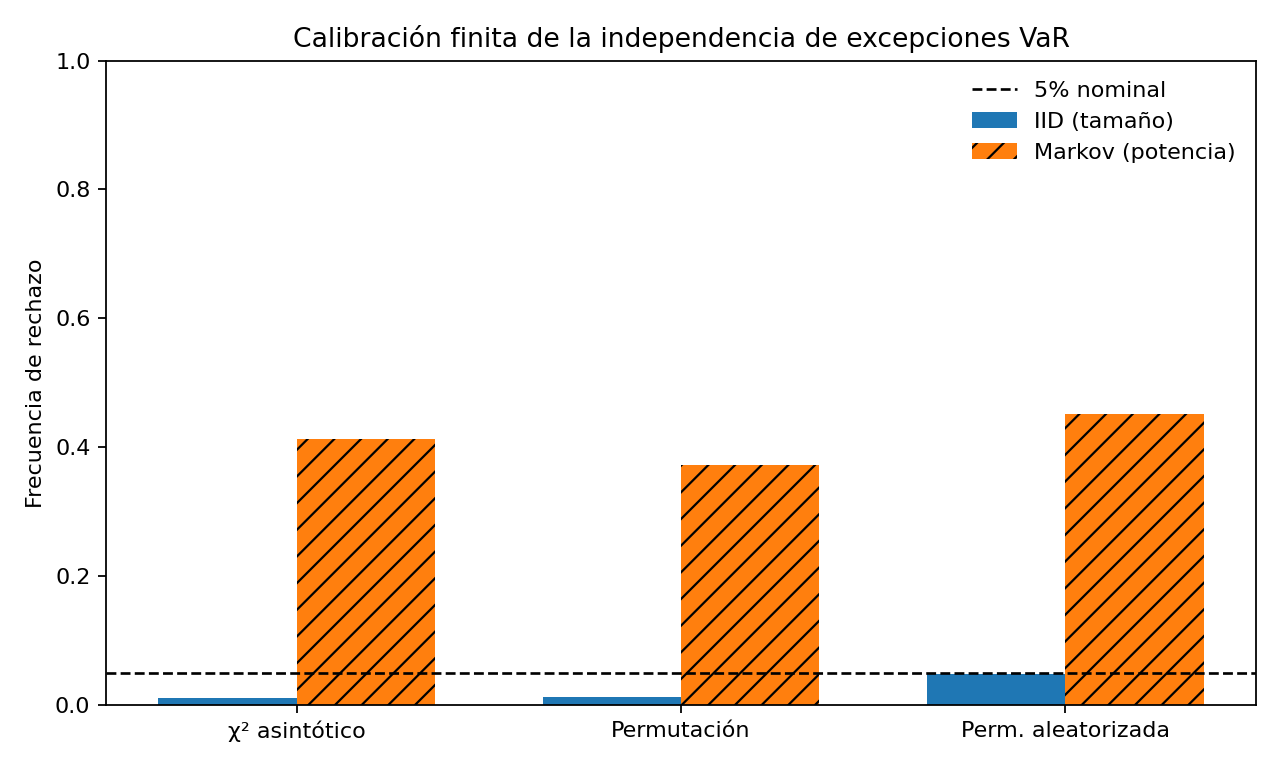

In [3]:
display(Image(filename=str(ROOT/'results'/'calibration.png')))

In [4]:
null = summary.query("scenario == 'iid_null'").iloc[0]
assert null.rejection_asymptotic < 0.03
assert null.rejection_permutation <= null.rejection_asymptotic + 0.01
assert abs(null.rejection_randomized - 0.05) < 0.02
summary

,scenario,mean_exception_rate,rejection_asymptotic,rejection_permutation,rejection_randomized
0,iid_null,0.010030,0.012,0.0125,0.0480
1,markov_clustered,0.009926,0.413,0.3730,0.4515


## Conclusiones y límites

La permutación no aleatorizada conserva validez pero no elimina necesariamente el conservadurismo: la discreción y los empates importan. Romper empates recupera el tamaño nominal, a costa de que decisiones marginales dependan de RNG. No es validación histórica ni incluye error de estimación del VaR; no debe usarse como único control regulatorio.